# Gaia epoch photometry of ATLAS J1013−4516

MIT Gaia DR4 Warm Up Workshop · November 5–6, 2026

## From sparse light curves to a longer orbital clock

- **Gaia epoch photometry** is a time series of individual brightness measurements, with times, flux uncertainties and quality information, rather than a single catalogue mean magnitude. DR3 provides G, BP and RP field-of-view (FoV) measurements for a selected subset of sources. The scanning law gives irregular, sky-dependent sampling over 34 months: typically tens of visits, rather than continuous coverage. DR3 published about **11.75 million photometric time series**, including variables and the Gaia Andromeda Photometric Survey ([Gaia Collaboration 2023](https://doi.org/10.1051/0004-6361/202243940)).

- **Precision depends on brightness, band and sampling.** Catalogue mean-flux precision is not the uncertainty of an individual epoch. For this faint target (catalogue G ≈ 19.5), the stored series contains **54 measurements over 1,010 days**, with a **median reported flux uncertainty of 1.80%** (approximately 19.6 mmag). The next cell verifies these values. These are reported statistical errors; the timing-template residuals provide a separate check.

- **What has it enabled?** Sparse sampling can still recover short periods: Steen et al. (2024) measured periods independently from Gaia for 105 white dwarfs, from 256.2 seconds to about 9.5 days, including seven below 1,000 seconds. Their median confirmed variability amplitude was 1.4%—an amplitude, not a per-epoch precision estimate ([paper](https://doi.org/10.3847/1538-4357/ad3e60)). For binaries, early photometry can also extend the orbital clock: a coherent waveform provides seasonal phase measurements, and curvature in an observed-minus-calculated (O–C) diagram constrains the period derivative.

- **What changes in DR4?** ESA's expected content includes a 66-month baseline, much broader light-curve availability, and both FoV photometry and **individual-CCD G-band photometry** (`epoch_photometry_ccd`). CCD measurements offer sampling within a transit, helping resolve rapid waveform structure that FoV averages smear. They share calibration and transit-level systematics, so more samples do not automatically mean equally many independent timings. These are planned products, pending validation as of this workshop ([ESA DR4 content](https://www.cosmos.esa.int/web/gaia/dr4)).

- **What I will show:** the Gaia/ATLAS fold of the 8.56-minute binary J1013; three seasonal Gaia timings measured directly from its stored fluxes; and the O–C and conditional $\dot P$ uncertainty **before and after** adding those timings to 12 non-Gaia epochs. No previously supplied Gaia timing epochs enter this notebook. The scientific opportunity is an earlier orbital clock; DR4 should make this approach available for many more targets and improve our view of rapid light-curve structure.

- The published result is $\dot P=(-1.60\pm0.07)\times10^{-12}$ s/s ([Chickles et al. 2026](https://doi.org/10.3847/1538-4357/ae4871)). This notebook's new Gaia timings are exploratory, with template and time-scale limitations described below; the before/after fit is a fresh calculation, not a reproduction of the published measurement.

Run All writes figures and numeric products to `figures/` and `tables/`.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation
from astropy.utils import iers
import astropy.units as u

# Run from this directory, or from its parent.
ROOT = Path.cwd()
if not (ROOT / 'data/source_manifest.json').exists():
    ROOT = ROOT / 'j1013_gaia_notebook'
if not (ROOT / 'data/source_manifest.json').exists():
    raise FileNotFoundError('Open the notebook with its bundled data/ directory beside it.')
DATA = ROOT / 'data'
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
TABLE = ROOT / 'tables'; TABLE.mkdir(exist_ok=True)
iers.conf.auto_download = False
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'savefig.dpi':220, 'figure.dpi':110})
COLORS = {'Gaia':'#202020','ATLAS-c':'#0072B2','ATLAS-o':'#E69F00',
          'ATLAS':'#E69F00','ULTRACAM':'#009E73','Proto-Lightspeed':'#CC79A7'}
T0_PUBLISHED = 60033.2044878
P_PUBLISHED_S = 513.593303
PDOT_PUBLISHED = -1.60e-12
N_PHASE_BINS = 50

def save_figure(fig, stem):
    for extension in ('pdf','png'):
        fig.savefig(FIG / f'{stem}.{extension}', bbox_inches='tight')

manifest = json.loads((DATA/'source_manifest.json').read_text())
for item in manifest:
    assert hashlib.sha256((ROOT/item['file']).read_bytes()).hexdigest() == item['sha256']
print(f'Verified checksums of {len(manifest)} source input files.')

intro_gaia = np.loadtxt(DATA/'gaia.dat')
relative_error = intro_gaia[:,3]/np.abs(intro_gaia[:,2])
print(f'J1013: {len(intro_gaia)} stored Gaia measurements over {np.ptp(intro_gaia[:,0]):.1f} days.')
print(f'Median reported flux error: {100*np.median(relative_error):.2f}% '
      f'(small-error magnitude equivalent {1000*2.5/np.log(10)*np.median(relative_error):.1f} mmag).')
print('Reported point errors, not empirical repeatability or eclipse-timing precision.')


Verified checksums of 5 source input files.
J1013: 54 stored Gaia measurements over 1010.0 days.
Median reported flux error: 1.80% (small-error magnitude equivalent 19.6 mmag).
Reported point errors, not empirical repeatability or eclipse-timing precision.


## 1. Gaia epoch photometry

`gaia.dat` contains 54 processed Gaia DR3 G-band measurements for source
**5414242958825679488**. Columns 0, 2, and 3 supply time, flux, and flux error.

The file lacks the original archive metadata, quality flags, and time-conversion record.
Times are used unchanged, with the original analysis's BMJD-TDB interpretation assumed.
That scale requires verification before interpreting absolute timing offsets. The second
column is a constant 0.0001 day (8.64 s); its meaning is undocumented and it is not used as an exposure time.


54 points; 1009.98-day baseline


,time_as_stored_days,column_1_undocumented,flux,flux_error,column_4_undocumented,column_5_undocumented
0,56876.258842,0.0001,285.369581,6.60243,1.0,1.0
1,56875.684530,0.0001,284.032582,6.41852,1.0,1.0
2,57021.535103,0.0001,359.464336,4.84959,1.0,1.0
3,57130.762592,0.0001,266.909311,4.74919,1.0,1.0
4,56876.759148,0.0001,264.432916,4.73226,1.0,1.0


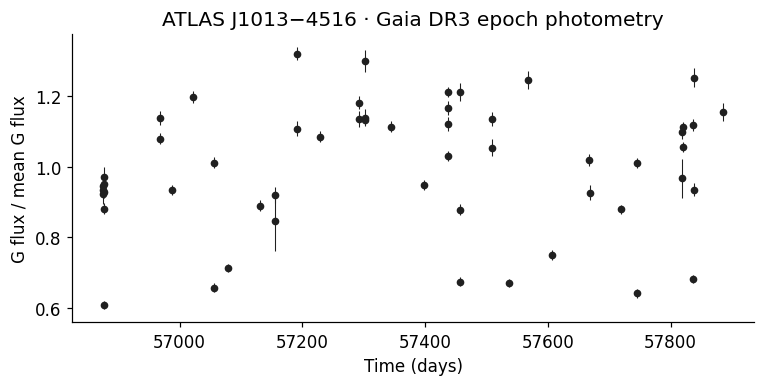

In [2]:
raw = np.loadtxt(DATA/'gaia.dat')
gaia = pd.DataFrame(raw, columns=['time_as_stored_days','column_1_undocumented',
                    'flux','flux_error','column_4_undocumented','column_5_undocumented'])
assert len(gaia) == 54
assert np.isfinite(gaia[['time_as_stored_days','flux','flux_error']]).all().all()
assert (gaia.flux_error > 0).all()
gaia.to_csv(TABLE/'gaia_epoch_photometry.csv',index=False)
print(f'{len(gaia)} points; {np.ptp(gaia.time_as_stored_days):.2f}-day baseline')
display(gaia.head())
fig, ax = plt.subplots(figsize=(8,3.4))
mean_flux = gaia.flux.mean()
ax.errorbar(gaia.time_as_stored_days,gaia.flux/mean_flux,
            gaia.flux_error/mean_flux,fmt='o',ms=4,color=COLORS['Gaia'],elinewidth=.7)
ax.set(xlabel='Time (days)',
       ylabel='G flux / mean G flux',title='ATLAS J1013−4516 · Gaia DR3 epoch photometry')
save_figure(fig,'j1013_gaia_epochs')
plt.show()


## 2. ATLAS photometry

The original ATLAS input is included as `atlas_reduced_original.txt`. Following the source
analysis, we select `chi/N < 10` and `mag5sig > 17`, match the c-band median to the o-band median,
and apply a pooled ±3-IQR flux cut. The fluxes are difference fluxes.

MJD UTC is converted to BMJD TDB using the source analysis's Palomar location and the coordinates
in `gaia_dr3.json`. This applies one site to all rows; a per-observatory time audit remains outstanding.


In [3]:
cols = ['MJD','m','dm','uJy','duJy','F','err','chiN','RA','Dec','x','y',
        'maj','min','phi','apfit','mag5sig','Sky','Obs']
atlas_raw = pd.read_csv(DATA/'atlas_reduced_original.txt',sep=r'\s+',comment='#',
                        names=cols,dtype={'F':str,'Obs':str})
atlas = atlas_raw.loc[(atlas_raw.chiN < 10) & (atlas_raw.mag5sig > 17)].copy()
n_quality = len(atlas)
delta_median = np.median(atlas.loc[atlas.F=='o','uJy']) - np.median(atlas.loc[atlas.F=='c','uJy'])
atlas.loc[atlas.F=='c','uJy'] += delta_median
iqr = np.diff(np.percentile(atlas.uJy,[25,75]))[0]
med = np.median(atlas.uJy)
atlas = atlas.loc[(atlas.uJy > med-3*iqr) & (atlas.uJy < med+3*iqr)].copy()
assert np.isfinite(atlas[['MJD','uJy','duJy']]).all().all() and (atlas.duJy > 0).all()
catalog = json.loads((DATA/'gaia_dr3.json').read_text())
coord = SkyCoord(catalog['coordinates']['ra_icrs_deg']*u.deg,
                 catalog['coordinates']['dec_icrs_deg']*u.deg)
palomar = EarthLocation.from_geocentric(-2410346.78217658*u.m,
                                       -4758666.82504051*u.m,3487942.97502457*u.m)
t = Time(atlas.MJD.to_numpy(),format='mjd',scale='utc')
atlas['bmjd_tdb'] = (t.tdb + t.tdb.light_travel_time(coord,kind='barycentric',location=palomar)).mjd
atlas.to_csv(TABLE/'atlas_cleaned_photometry.csv',index=False)
print(f'ATLAS: {len(atlas_raw)} input → {n_quality} quality-selected → {len(atlas)} IQR-selected')
display(atlas.groupby('F').agg(n=('uJy','size'),first_mjd=('MJD','min'),last_mjd=('MJD','max')))


ATLAS: 2128 input → 2007 quality-selected → 1946 IQR-selected


,n,first_mjd,last_mjd
F,,,
c,449,57453.407532,60648.321291
g,8,58195.330590,58195.424552
o,1489,57404.516962,60654.049231


## 3. Gaia/ATLAS phase-folded light curves

We use the published quadratic ephemeris and inverse-variance averages in 50 phase bins.
Gaia flux is normalized by its mean. Each ATLAS band's folded flux is shifted and scaled to
match Gaia's folded interquartile range, following the original comparison figure.

The overlay compares waveform shapes rather than absolute amplitudes or colors. The three
displayed cycles repeat the same measurements. This fold uses the published ephemeris; it does
not independently estimate a period or period derivative.


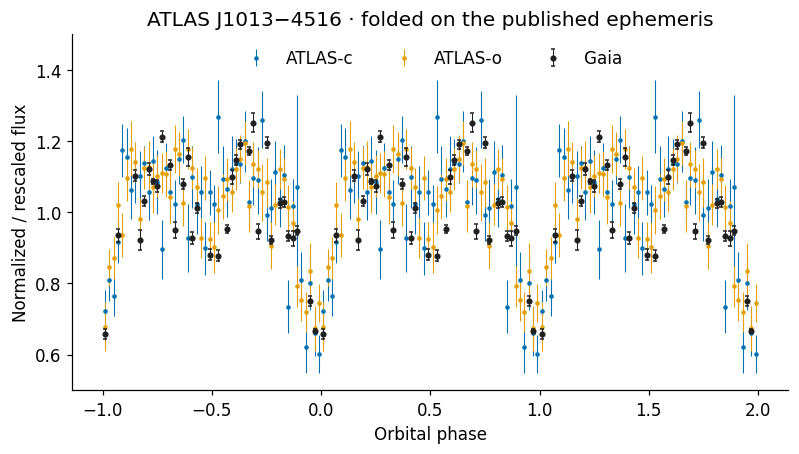

In [4]:
def phase_fold(time, period_days, pdot, t0):
    dt = np.asarray(time)-t0
    return ((dt - .5*pdot/period_days*dt**2) % period_days)/period_days

def binned_fold(time, flux, error):
    phase = phase_fold(time,P_PUBLISHED_S/86400,PDOT_PUBLISHED,T0_PUBLISHED)
    edges = np.linspace(0,1,N_PHASE_BINS+1)
    result = []
    for lo,hi in zip(edges[:-1],edges[1:]):
        m = (phase >= lo) & (phase < hi)
        if m.any():
            w = 1/np.asarray(error)[m]**2
            result.append([(lo+hi)/2,np.sum(np.asarray(flux)[m]*w)/w.sum(),np.sqrt(1/w.sum())])
        else:
            result.append([(lo+hi)/2,np.nan,np.nan])
    return np.asarray(result)

def repeated_cycles(binned):
    return np.vstack([binned+[-1,0,0],binned,binned+[1,0,0]])

g = binned_fold(gaia.time_as_stored_days,gaia.flux/mean_flux,gaia.flux_error/mean_flux)
# Quantiles of the repeated arrays reproduce the original notebook exactly.
qg = np.nanpercentile(repeated_cycles(g)[:,1],[25,75])
folds = {'Gaia':g}
transforms = []
for band in ('c','o'):
    d = atlas.loc[atlas.F==band]
    y,dy = d.uJy.to_numpy(),d.duJy.to_numpy()
    if band == 'o':
        dy = dy/y.mean(); y = y/y.mean()
    binned = binned_fold(d.bmjd_tdb,y,dy)
    q = np.percentile(repeated_cycles(binned)[:,1],[25,75])
    scale = np.diff(qg)[0]/np.diff(q)[0]
    offset = qg[0]-scale*q[0]
    binned[:,1] = scale*binned[:,1]+offset
    binned[:,2] *= scale
    folds[f'ATLAS-{band}'] = binned
    transforms.append(dict(band=band,scale=scale,offset=offset))
pd.DataFrame(transforms).to_csv(TABLE/'atlas_display_transforms.csv',index=False)
all_folds = pd.concat([pd.DataFrame(a,columns=['phase','display_flux','display_flux_error']).assign(survey=label)
                       for label,a in folds.items()],ignore_index=True)
all_folds.to_csv(TABLE/'gaia_atlas_folded_50bins.csv',index=False)

fig, ax = plt.subplots(figsize=(8.4,4.2))
for label in ('ATLAS-c','ATLAS-o','Gaia'):
    b = repeated_cycles(folds[label])
    ax.errorbar(b[:,0],b[:,1],b[:,2],fmt='o' if label=='Gaia' else '.',
                ms=3 if label=='Gaia' else 4,elinewidth=.7,capsize=1 if label=='Gaia' else 0,
                color=COLORS[label],label=label,zorder=3 if label=='Gaia' else 2)
ax.set(xlabel='Orbital phase',ylabel='Normalized / rescaled flux',ylim=(.5,1.5),
       title='ATLAS J1013−4516 · folded on the published ephemeris')
ax.legend(ncol=3,loc='upper center',frameon=False)
save_figure(fig,'j1013_gaia_atlas_fold')
plt.show()


## 4. Non-Gaia timing epochs

`other_timing_epochs.csv` contains 12 epochs: seven ULTRACAM, three ATLAS and two
Proto-Lightspeed timings. Instrument assignments follow the original figure annotations.
The stored time scale is assumed to be BMJD TDB. The uncertainty used is `sigma_s`;
the day-unit version was rounded. Integer cycles are reconstructed from the stored reference
period. Previously supplied Gaia timing rows are excluded from the input files and analysis.


In [5]:
epochs = pd.read_csv(DATA/'other_timing_epochs.csv')
assert len(epochs)==12 and not (epochs.instrument=='Gaia').any()
np.testing.assert_allclose(epochs.sigma_s,epochs.sigma_days*86400,atol=0.005)
T_REF = float(epochs.iloc[0].time_as_stored_days)
P_REF_D = float(epochs.iloc[0].reference_period_days)
P_REF_S = P_REF_D*86400
epochs['cycle_integer'] = np.rint(epochs.dt_days/P_REF_D).astype('int64')
np.testing.assert_allclose((epochs.dt_days-epochs.cycle_integer*P_REF_D)*86400,epochs.oc_s,atol=1e-5)
epochs['year_for_display'] = Time(epochs.time_as_stored_days.to_numpy(),format='mjd',scale='tdb').decimalyear
print(f'Common linear reference: T_ref = {T_REF:.10f}, P_ref = {P_REF_S:.12f} s')
display(epochs[['instrument','time_as_stored_days','cycle_integer','oc_s','sigma_s']].sort_values('time_as_stored_days'))


Common linear reference: T_ref = 60033.2044883359, P_ref = 513.593300316548 s


,instrument,time_as_stored_days,cycle_integer,oc_s,sigma_s
7,ATLAS,58300.325977,-291516,-38.877951,8.531964
8,ATLAS,59100.010048,-156988,-14.646860,5.193422
9,ATLAS,59657.217320,-63251,-1.495497,3.861625
0,ULTRACAM,60033.204488,0,0.000000,0.434442
1,ULTRACAM,60034.262585,178,-0.050503,0.691042
2,ULTRACAM,60347.382093,52853,-1.626978,1.264423
3,ULTRACAM,60348.214297,52993,-2.252206,1.650222
4,ULTRACAM,60675.279283,108014,-4.497383,0.756526
5,ULTRACAM,60727.268718,116760,-4.315182,0.742279
6,ULTRACAM,60763.172679,122800,-5.587977,0.777115


## 5. A common timing fit for the before/after comparison

For both sets we fit $O-C=a+b(E/10^5)+c(E/10^5)^2$ by weighted least squares,
where $E$ is integer cycle count on the same linear reference ephemeris.
The local period is $P=P_{\rm ref}+b/10^5$ and $\dot P=2(c/10^{10})/P$.
We propagate the full coefficient covariance to $\dot P$. Formal errors use the supplied
non-Gaia timing errors and the residual-scaled Gaia profile errors below; the joint fit
applies no additional reduced-$\chi^2$ rescaling. The final panels share axes and reference.


In [6]:
def timing_design(cycles):
    x = np.asarray(cycles)/1e5
    return np.column_stack([np.ones_like(x),x,x*x])

def fit_timing(frame):
    X = timing_design(frame.cycle_integer.to_numpy())
    sigma = frame.sigma_s.to_numpy()
    Xw = X/sigma[:,None]
    beta = np.linalg.lstsq(Xw,frame.oc_s.to_numpy()/sigma,rcond=None)[0]
    covariance = np.linalg.inv(Xw.T@Xw)
    period = P_REF_S+beta[1]/1e5
    pdot = 2*beta[2]/1e10/period
    gradient = np.array([0.,-pdot/(period*1e5),2/(1e10*period)])
    uncertainty = np.sqrt(gradient@covariance@gradient)
    residual = frame.oc_s.to_numpy()-X@beta
    return dict(beta=beta,covariance=covariance,pdot=pdot,sigma=uncertainty,
                chi2=float(np.sum((residual/sigma)**2)),dof=len(frame)-3,n=len(frame))

before = fit_timing(epochs)
print(f'Before Gaia: Pdot = ({before["pdot"]/1e-12:.3f} ± {before["sigma"]/1e-12:.3f}) × 10^-12 s/s')


Before Gaia: Pdot = (-1.728 ± 0.168) × 10^-12 s/s


## 6. Measure seasonal Gaia epochs from photometry

We fit the saved high-speed g-band LCURVE waveform to each Gaia season with a free time shift,
positive amplitude, and flux offset. The model geometry is fixed; its saved conjunction phase
sets the template zero point. We use explicit boundaries at 57200 and 57600 days, yielding
20, 19, and 15 measurements. The original analysis's three-season selection is unknown.

Within-season phase evolution comes from a quadratic ephemeris fitted to the **12 non-Gaia
timings only**, while each Gaia seasonal shift remains free. The published Pdot is not imposed.
Uncertainty in this external phase evolution is not propagated, so the timing errors are conditional.

Each reported epoch is the integer cycle nearest the inverse-variance-weighted mean observing
cycle of its season. No supplied Gaia timings are used, including for reporting-cycle selection.
Times remain on the stored scale. Two measurements are about 4 ms apart; their independence
cannot be checked without transit IDs, and both are retained.


In [7]:
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar, brentq

# Fit only the non-Gaia timing rows for phase evolution within each season.
external = pd.read_csv(DATA/'other_timing_epochs.csv')
E_ext = np.rint(external.dt_days.to_numpy()*86400/P_REF_S).astype('int64')
X_ext = np.column_stack([np.ones(len(E_ext)),E_ext/1e5,(E_ext/1e5)**2])
w_ext = 1/external.sigma_s.to_numpy()
b_ext = np.linalg.lstsq(X_ext*w_ext[:,None],external.oc_s.to_numpy()*w_ext,rcond=None)[0]
EXT_A = b_ext[0]
EXT_P = P_REF_S+b_ext[1]/1e5
EXT_C = b_ext[2]/1e10

def external_epoch(cycle):
    return T_REF+(EXT_A+EXT_P*np.asarray(cycle)+EXT_C*np.asarray(cycle)**2)/86400

def external_cycles(time):
    dt = (np.asarray(time)-T_REF)*86400-EXT_A
    # Stable inverse of dt = P E + C E^2.
    return 2*dt/(EXT_P+np.sqrt(EXT_P**2+4*EXT_C*dt))

model = np.loadtxt(DATA/'ultracam_g_lcurve_template.dat')
template_meta = json.loads((DATA/'template_metadata.json').read_text())
xp = model[:,0]-template_meta['phase_conjunction']
yp = model[:,2]/np.mean(model[:,2])
assert np.isclose(xp[0],0) and np.isclose(xp[-1],1)
assert np.isclose(yp[0],yp[-1],atol=1e-8)
yp[-1] = yp[0]  # exactly close the periodic spline (roundoff only)
timing_template = CubicSpline(xp,yp,bc_type='periodic')
print(f'Non-Gaia-only phase evolution: Pdot = {2*EXT_C/EXT_P/1e-12:.3f} × 10^-12 s/s')
print('Gaia seasonal shifts are fitted to the individual flux measurements.')


Non-Gaia-only phase evolution: Pdot = -1.728 × 10^-12 s/s
Gaia seasonal shifts are fitted to the individual flux measurements.


### Timing profiles and sensitivity checks

The nominal model averages the waveform over a **44-second uniform boxcar**. This is an assumed
response, because the effective response is undocumented in the input. We also fit with zero
additional averaging. At each trial shift, amplitude and offset are solved analytically; the
search covers one orbital cycle and refines the best minimum.

The error interval is the contiguous region around that minimum satisfying

$$\Delta\chi^2\leq\max[1,\chi^2_{\min}/(N-3)].$$

This scales the local profile errors by the residual scatter when the fit is poor. It does not
account for waveform-transfer errors, correlated measurements, the time scale, or uncertainty
in phase evolution. We also allow a first-harmonic sine/cosine baseline to test waveform and
eclipse-label sensitivity. The resulting epochs are exploratory.


In [8]:
def fit_gaia_season(t,y,error,exposure_s=44.0,harmonic=False):
    t,y,error = map(np.asarray,(t,y,error))
    base_phase = external_cycles(t) % 1
    nuisance = np.column_stack([np.ones(len(t)),np.cos(2*np.pi*base_phase),np.sin(2*np.pi*base_phase)]) if harmonic else np.ones((len(t),1))
    # Weighted projection removes nuisance coefficients at every trial shift.
    Q,_ = np.linalg.qr(nuisance/error[:,None],mode='reduced')
    yw = y/error
    yr = yw-Q@(Q.T@yw)
    offsets = ((np.arange(21)+.5)/21-.5)*exposure_s

    def template_at(shifts):
        shifts = np.atleast_1d(shifts)
        tt = t[None,:,None]+(offsets[None,None,:]-shifts[:,None,None])/86400
        return timing_template(external_cycles(tt)%1).mean(axis=2)

    def profile(shifts):
        m = template_at(shifts)/error[None,:]
        mr = m-(m@Q)@Q.T
        denom = np.sum(mr*mr,axis=1)
        amplitude = (mr@yr)/denom
        chi = yr@yr-(mr@yr)**2/denom
        return np.where(amplitude>0,np.maximum(chi,0),1e30)

    grid = np.linspace(-P_REF_S/2,P_REF_S/2,2049)
    chi = profile(grid)
    i = int(np.argmin(chi))
    opt = minimize_scalar(lambda sh:float(profile([sh])[0]),
            bounds=(grid[max(0,i-1)],grid[min(len(grid)-1,i+1)]),method='bounded',options={'xatol':1e-7})
    shift,cmin = float(opt.x),float(opt.fun)
    n_parameters = nuisance.shape[1]+2  # nuisance + template amplitude + shift
    dof = len(t)-n_parameters
    error_scale = max(1,cmin/dof)
    threshold = cmin+error_scale

    def crossing(direction):
        trial = shift+direction*np.linspace(0,P_REF_S/2,2049)
        v = profile(trial)-threshold
        hits = np.flatnonzero(v>0)
        if not len(hits): return np.nan
        j = int(hits[0])
        return brentq(lambda sh:float(profile([sh])[0]-threshold),*sorted([trial[j-1],trial[j]]),xtol=1e-7)
    lower,upper = crossing(-1),crossing(1)
    X = np.column_stack([template_at([shift])[0],nuisance])
    coeff = np.linalg.lstsq(X/error[:,None],yw,rcond=None)[0]
    circular_distance = np.abs((grid-shift+P_REF_S/2)%P_REF_S-P_REF_S/2)
    opposite = circular_distance > P_REF_S/4
    return dict(shift_s=shift,error_minus_s=shift-lower,error_plus_s=upper-shift,
                chi2=cmin,dof=dof,chi2nu=cmin/dof,error_scale=error_scale,
                opposite_half_delta_chi2=(float(chi[opposite].min()-cmin) if chi[opposite].min()<1e29 else np.nan),
                grid=grid,chi2_profile=chi,coeff=coeff,profile=profile,
                template_at=template_at,model=X@coeff)

# Sign/units sanity check at the actual cadence: an exact shifted template must be recovered.
test_t = gaia.time_as_stored_days.to_numpy()[:20]
test_offsets = ((np.arange(21)+.5)/21-.5)*44
injected_shift_s = 7.25
test_y = .15+1.2*timing_template(external_cycles(test_t[:,None]+(test_offsets-injected_shift_s)/86400)%1).mean(axis=1)
injected = fit_gaia_season(test_t,test_y,np.full(len(test_t),.02))
assert abs(injected['shift_s']-injected_shift_s)<0.005
print(f'Synthetic shift recovery: injected {injected_shift_s:.3f} s, recovered {injected["shift_s"]:.3f} s')


Synthetic shift recovery: injected 7.250 s, recovered 7.250 s


,season,n,time_as_stored_days,oc_s,error_minus_s,error_plus_s,chi2nu
0,1,20,56995.822002,-105.306066,11.805060,10.804857,34.269343
1,2,19,57410.655932,-75.877183,8.663374,7.658741,15.685821
2,3,15,57769.125023,-76.771403,8.162911,8.013673,19.720447


,season,variant,shift_s,delta_from_nominal_s,chi2nu,half_cycle_switch
0,1,44s fixed template,14.972866,0.000000,34.269343,False
1,1,0s extra smearing,18.282125,3.309260,33.953662,False
2,1,44s + first-harmonic baseline,-244.541868,254.078567,29.298732,True
3,2,44s fixed template,14.320772,0.000000,15.685821,False
4,2,0s extra smearing,14.230907,-0.089865,15.812283,False
5,2,44s + first-harmonic baseline,-242.296254,-256.617026,12.189320,True
6,3,44s fixed template,-9.085730,0.000000,19.720447,False
7,3,0s extra smearing,-10.002415,-0.916686,18.856396,False
8,3,44s + first-harmonic baseline,-6.924109,2.161621,20.147238,False


Profile errors are conditional; inspect χ² and the eclipse-label sensitivity before interpreting the epochs.


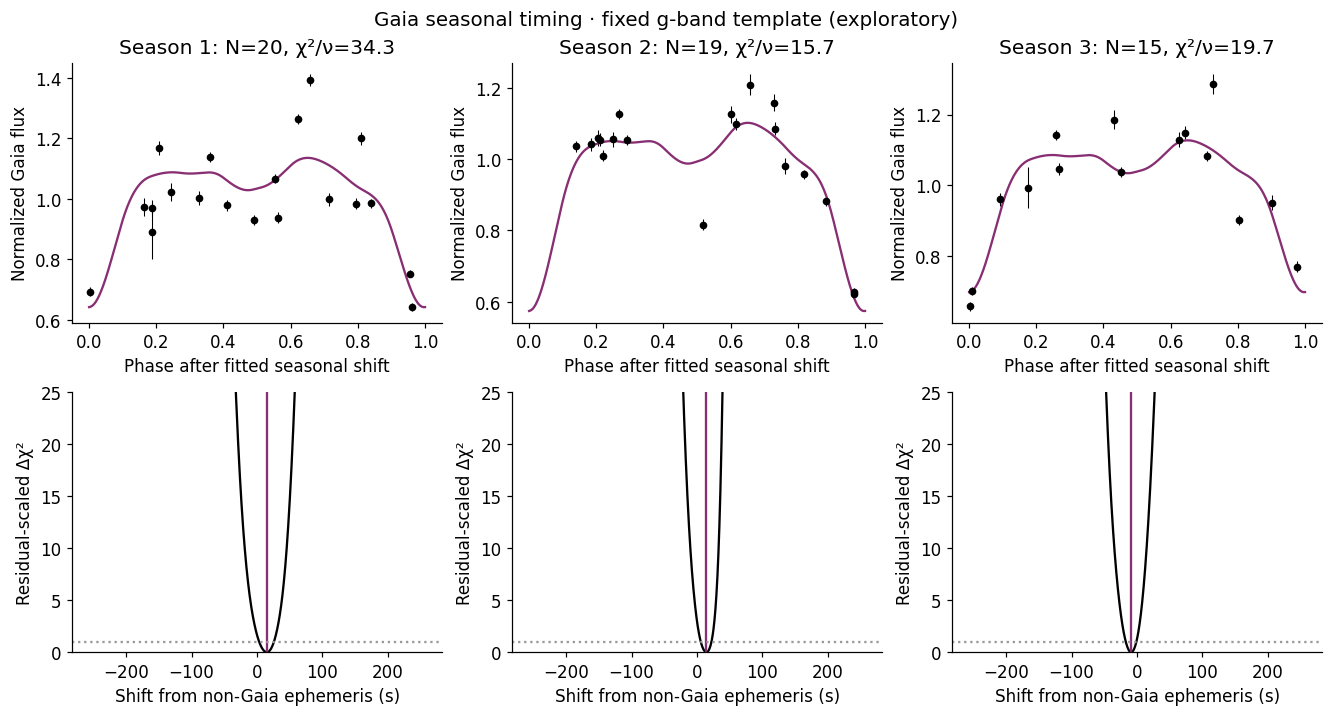

In [9]:
SEASON_EDGES = [-np.inf,57200,57600,np.inf]
measured_rows, sensitivity_rows, season_fits = [],[],[]
for j,(lo,hi) in enumerate(zip(SEASON_EDGES[:-1],SEASON_EDGES[1:])):
    d = gaia.loc[(gaia.time_as_stored_days>=lo)&(gaia.time_as_stored_days<hi)]
    t = d.time_as_stored_days.to_numpy()
    mean = d.flux.mean(); y = d.flux.to_numpy()/mean; error = d.flux_error.to_numpy()/mean
    result = fit_gaia_season(t,y,error)
    unsmeared = fit_gaia_season(t,y,error,exposure_s=0)
    flexible = fit_gaia_season(t,y,error,harmonic=True)
    # Report a conjunction near the weighted centre of the observed season.
    report_cycle = int(np.rint(np.average(external_cycles(t),weights=1/error**2)))
    measured_time = float(external_epoch(report_cycle)+result['shift_s']/86400)
    measured_oc = (measured_time-(T_REF+report_cycle*P_REF_D))*86400
    row = dict(season=j+1,n=len(t),first_time_as_stored_days=t.min(),last_time_as_stored_days=t.max(),
               cycle_integer=report_cycle,time_as_stored_days=measured_time,oc_s=measured_oc,
               sigma_s=max(result['error_minus_s'],result['error_plus_s']),
               error_minus_s=result['error_minus_s'],error_plus_s=result['error_plus_s'],
               shift_from_non_gaia_ephemeris_s=result['shift_s'],chi2nu=result['chi2nu'],
               opposite_half_delta_chi2=result['opposite_half_delta_chi2'],
               status='Exploratory fixed-template remeasurement; time scale assumed as stored')
    measured_rows.append(row)
    for label,fit in [('44s fixed template',result),('0s extra smearing',unsmeared),('44s + first-harmonic baseline',flexible)]:
        delta = (fit['shift_s']-result['shift_s']+P_REF_S/2)%P_REF_S-P_REF_S/2
        sensitivity_rows.append(dict(season=j+1,variant=label,shift_s=fit['shift_s'],
                 delta_from_nominal_s=delta,chi2nu=fit['chi2nu'],half_cycle_switch=abs(delta)>P_REF_S/4))
    season_fits.append(dict(data=d,t=t,y=y,error=error,result=result))

measured_gaia = pd.DataFrame(measured_rows)
timing_sensitivity = pd.DataFrame(sensitivity_rows)
measured_gaia.to_csv(TABLE/'gaia_measured_timing_epochs.csv',index=False)
timing_sensitivity.to_csv(TABLE/'gaia_timing_sensitivity.csv',index=False)
display(measured_gaia[['season','n','time_as_stored_days','oc_s','error_minus_s','error_plus_s','chi2nu']])
display(timing_sensitivity)
print('Profile errors are conditional; inspect χ² and the eclipse-label sensitivity before interpreting the epochs.')

fig,axes = plt.subplots(2,3,figsize=(12,6.4),layout='constrained')
for j,group in enumerate(season_fits):
    t,y,error,result = group['t'],group['y'],group['error'],group['result']
    ph = external_cycles(t-result['shift_s']/86400)%1
    ax = axes[0,j];ax.errorbar(ph,y,error,fmt='o',ms=4,color='k',elinewidth=.7)
    pp = np.linspace(0,1,600)
    smooth = timing_template((pp[:,None]+(((np.arange(21)+.5)/21-.5)*44/EXT_P))%1).mean(axis=1)
    ax.plot(pp,result['coeff'][0]*smooth+result['coeff'][1],color='#882E72')
    ax.set(xlabel='Phase after fitted seasonal shift',ylabel='Normalized Gaia flux',title=f'Season {j+1}: N={len(t)}, χ²/ν={result["chi2nu"]:.1f}')
    ax = axes[1,j]
    ax.plot(result['grid'],(result['chi2_profile']-result['chi2'])/result['error_scale'],color='k')
    ax.axvline(result['shift_s'],color='#882E72');ax.axhline(1,color='.6',ls=':')
    ax.set(xlabel='Shift from non-Gaia ephemeris (s)',ylabel='Residual-scaled Δχ²',ylim=(0,25))
fig.suptitle('Gaia seasonal timing · fixed g-band template (exploratory)',fontsize=13)
save_figure(fig,'j1013_gaia_timing_profiles')
plt.show()


## 7. Before and after adding the flux-derived Gaia timings

The left panel uses only the 12 non-Gaia epochs; the right adds the three epochs measured
above. Both fits use the same model, linear reference, axes and formal-covariance calculation.
For Gaia we use the larger asymmetric profile error. Shaded bands are pointwise 1σ model bands.

The uncertainty reduction is **conditional**, not a validated improvement in total accuracy.
Gaia timings depend on the non-Gaia within-season ephemeris, whose uncertainty and resulting
cross-correlations are not propagated. The g-to-G template transfer, assumed response,
possible half-cycle switches, unknown stored time scale and correlated points remain relevant.
The sensitivity table above shows why these measurements should remain exploratory.


,dataset,n_epochs,pdot_s_per_s,conditional_sigma_s_per_s,chi2,dof
0,Without Gaia,12,-1.728180e-12,1.677485e-13,3.960245,9
1,With flux-derived Gaia,15,-1.650306e-12,7.339677e-14,8.348711,12


Conditional formal uncertainty: 0.168 → 0.073 × 10^-12 s/s
2.29× smaller; 56.2% reduction. Not a total systematic-error budget.


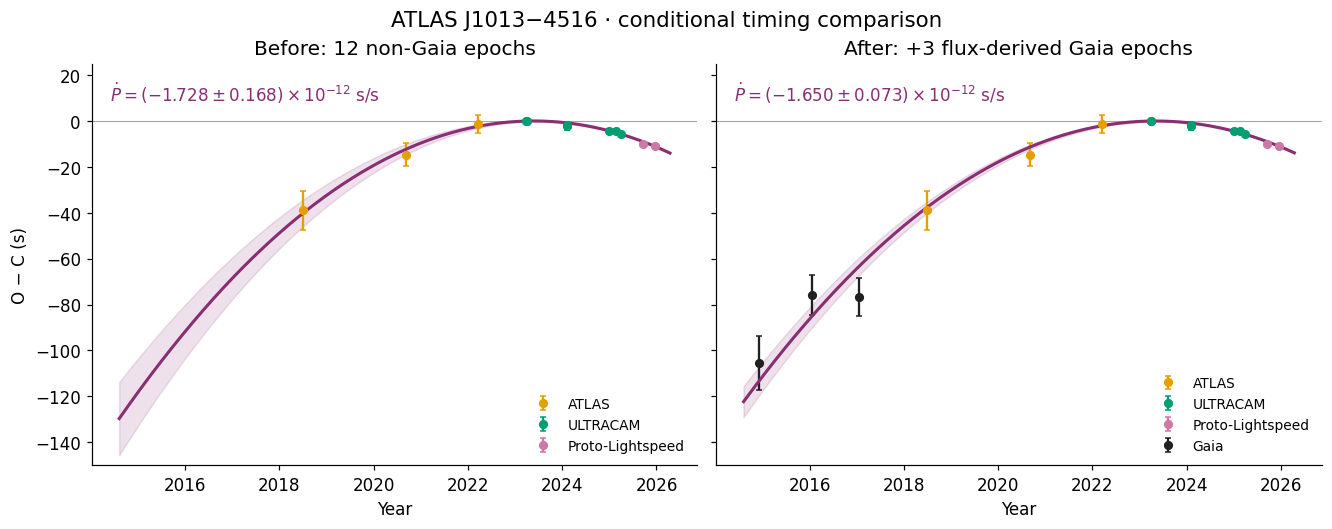

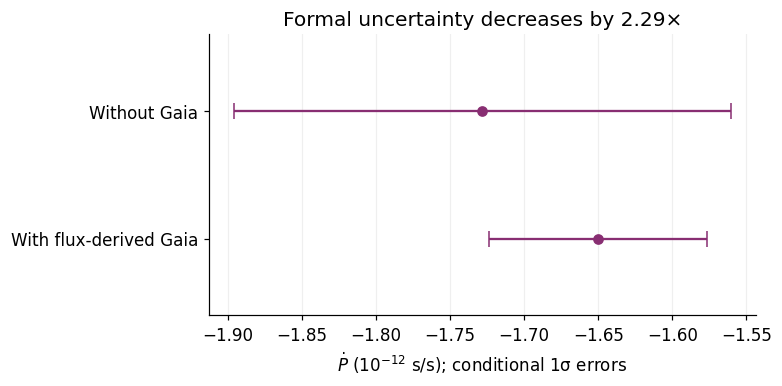

In [10]:
fresh = measured_gaia[['time_as_stored_days','sigma_s','cycle_integer','oc_s']].copy()
fresh['instrument'] = 'Gaia'
remeasured = pd.concat([epochs[['time_as_stored_days','sigma_s','cycle_integer','oc_s','instrument']],fresh],ignore_index=True)
remeasured['year_for_display'] = Time(remeasured.time_as_stored_days.to_numpy(),format='mjd',scale='tdb').decimalyear
after = fit_timing(remeasured)
comparison = pd.DataFrame([dict(dataset=label,n_epochs=fit['n'],pdot_s_per_s=fit['pdot'],
    conditional_sigma_s_per_s=fit['sigma'],chi2=fit['chi2'],dof=fit['dof'])
    for label,fit in [('Without Gaia',before),('With flux-derived Gaia',after)]])
comparison.to_csv(TABLE/'pdot_before_after_gaia.csv',index=False)
remeasured.sort_values('time_as_stored_days').to_csv(TABLE/'timing_epochs_remeasured_gaia.csv',index=False)
improvement = before['sigma']/after['sigma']
summary = dict(comparison=comparison.to_dict(orient='records'),formal_error_improvement_factor=improvement,
    status='Exploratory; formal errors conditional on timing and template assumptions',
    gaia_response_assumption_s=44,gaia_reporting_cycle='Inverse-variance-weighted observing-cycle centre',
    unresolved_systematics=['Stored Gaia time scale','g-to-G template transfer','half-cycle labeling',
                           'correlated measurements','external intra-season ephemeris uncertainty'])
(TABLE/'oc_remeasured_gaia_summary.json').write_text(json.dumps(summary,indent=2))
display(comparison)
print(f'Conditional formal uncertainty: {before["sigma"]/1e-12:.3f} → {after["sigma"]/1e-12:.3f} × 10^-12 s/s')
print(f'{improvement:.2f}× smaller; {100*(1-1/improvement):.1f}% reduction. Not a total systematic-error budget.')

cycle_grid = np.linspace(remeasured.cycle_integer.min()-20000,remeasured.cycle_integer.max()+20000,600)
Xg = timing_design(cycle_grid)
years = Time(T_REF+cycle_grid*P_REF_D,format='mjd',scale='tdb').decimalyear
fig,axes = plt.subplots(1,2,figsize=(12,4.7),sharex=True,sharey=True,layout='constrained')
for ax,frame,fit,title in zip(axes,[epochs,remeasured],[before,after],['Before: 12 non-Gaia epochs','After: +3 flux-derived Gaia epochs']):
    for instrument in ('ATLAS','ULTRACAM','Proto-Lightspeed','Gaia'):
        d = frame.loc[frame.instrument==instrument]
        if len(d):
            ax.errorbar(d.year_for_display,d.oc_s,d.sigma_s,fmt='o',ms=5,capsize=2,
                        color=COLORS[instrument],label=instrument)
    curve = Xg@fit['beta']
    band = np.sqrt(np.einsum('ij,jk,ik->i',Xg,fit['covariance'],Xg))
    ax.plot(years,curve,color='#882E72',lw=2)
    ax.fill_between(years,curve-band,curve+band,color='#882E72',alpha=.14)
    ax.axhline(0,color='.65',lw=.7,zorder=0)
    ax.set(xlabel='Year',title=title,ylim=(-150,25))
    ax.text(.03,.96,rf'$\dot P=({fit["pdot"]/1e-12:.3f}\pm{fit["sigma"]/1e-12:.3f})\times10^{{-12}}$ s/s',
            va='top',transform=ax.transAxes,fontsize=11,color='#882E72')
    ax.legend(loc='lower right',fontsize=9,frameon=False)
axes[0].set_ylabel('O − C (s)')
fig.suptitle('ATLAS J1013−4516 · conditional timing comparison',fontsize=14)
save_figure(fig,'j1013_oc_before_after_gaia')
plt.show()

fig,ax = plt.subplots(figsize=(7,3.4),layout='constrained')
labels = ['Without Gaia','With flux-derived Gaia']
values = comparison.pdot_s_per_s.to_numpy()/1e-12
errors = comparison.conditional_sigma_s_per_s.to_numpy()/1e-12
ax.errorbar(values,[1,0],xerr=errors,fmt='o',color='#882E72',capsize=5)
ax.set(yticks=[1,0],yticklabels=labels,ylim=(-.6,1.6),
       xlabel=r'$\dot P$ ($10^{-12}$ s/s); conditional 1σ errors',
       title=f'Formal uncertainty decreases by {improvement:.2f}×')
ax.grid(axis='x',alpha=.2)
save_figure(fig,'j1013_pdot_before_after_gaia')
plt.show()


## Data provenance and outputs

Inputs are author-provided analysis products for ATLAS J1013−4516. Original analysis-relative
filenames and SHA256 checksums are in `data/source_manifest.json`. The non-Gaia timing CSV
retains source-row identifiers for traceability; supplied Gaia timing rows are not bundled.

The folded comparison follows `scripts/gaia/plot_gaia_atlas.ipynb` and `utils/photometry.py`
in the source analysis. The template is `results/lcurve/good/good_model_g.dat`, with phase
origin from `good.mod`. The original Gaia archive response and ingestion documentation have
not been located; `gaia.dat` is a processed analysis product, with release unconfirmed.
The seasonal timing estimator and assumptions are specified in section 6.

PDF/PNG figures are written to `figures/`. `tables/pdot_before_after_gaia.csv` contains the
two fits, `gaia_measured_timing_epochs.csv` the new seasonal timings, and
`gaia_timing_sensitivity.csv` the waveform checks. The joint timing table contains only
non-Gaia inputs and the newly measured Gaia epochs.
